# What is the zero rule tied to? Correlates outside A998

`sequential_zero_consistency` showed a student-level ability to apply `n×0 = 0` that survives general multiplication
level and speed and generalises across operands and order. `cognitive_predictors` found WM and matrices predict it, but
modestly (OR ≈ 1.3 per SD, 375 students). Here: **which other measured profiles go with a good zero rule?**

**Sources** — ConMAT (Innovamat curricular test, same academic year, PRE and/or POST; ~64k / ~70k A998 students),
the socio-emotional test (MAES, ~1k students, exploratory), and COSMOS 2023-24 refitted in this notebook's model.

**Outcome** — the student's 0-fact accuracy (k correct of n, 0×0 excluded, 0×1 included; #36). **Models**, binomial GLM,
SEs clustered by school (A998 ES_2024 has no classroom id):
- **M1** `zero ~ indicator + retrieval accuracy + retrieval speed + age` — beyond being fluent and fast at multiplication.
- **M2** M1 + the **rest of ConMAT** (all other items): what a subscore adds beyond general curricular maths.
- The same models on the **1-facts** are the specificity check: a correlate of *the zero rule* should not predict `n×1`.

**Design** — discover on ES_2024, confirm on ES_2025 students who are **not** in the ES_2024 sample (independent).
Hit = Holm p < .05 over the 11 subscores in M2, ES_2024. Replicated = Holm p < .05 over the hits in ES_2025, same sign.

**Effect size** — log-OR per SD on the latent scale, β = ln(OR)·√3/π (SDs of the residual latent propensity per SD of the
predictor, controls held),
labelled with Kraft's (2020) education benchmarks: < .05 small, .05–.20 medium, ≥ .20 large. DECISIONS #71–#76.

In [1]:
import re, sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt, numpy as np, pandas as pd, statsmodels.api as sm
from scipy.stats import norm
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
from cached_query import cached_query
from paired_stats import holm
from plot_style import C_OTHER, C_ZERO, FONT_BIG, FONT_MED, paint_it_black, set_style
Q, CACHE, PLOTS = ROOT / "queries", ROOT / "cache", ROOT / "analysis" / "plots"; PLOTS.mkdir(exist_ok=True)
set_style(); warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

DISC, CONF, MIN_RETR = "ES_2024", "ES_2025", 5
BLOCK = {**dict.fromkeys(["reports_conmat_graphics_0021", "reports_conmat_graphics_0032"], "Number & operations"),
         **dict.fromkeys(["reports_conmat_graphics_0022", "reports_conmat_graphics_0033"], "Geometry"),
         "reports_conmat_graphics_0023": "Measurement",
         **dict.fromkeys(["reports_conmat_graphics_0024", "reports_conmat_graphics_0034"], "Statistics & probability"),
         **dict.fromkeys(["reports_conmat_graphics_0025", "reports_conmat_graphics_0035"], "Algebra")}
BLOCKS = ["Number & operations", "Geometry", "Measurement", "Statistics & probability", "Algebra"]
DOMAINS = ["Conceptual content", "Procedural content", "Problem Solving", "Reasoning and Proof", "Connections",
           "Communication and Representation"]
TAGS = BLOCKS + DOMAINS
FACTORS = ["working_memory", "reasoning", "execution_speed", "number_knowledge", "magnitude_comparison",
           "numeric_line", "arithmetic_fluency"]

# ---------- data ----------
zf = lambda s: (s - s.mean()) / s.std()
elogit = lambda k, n: np.log((k + .5) / (n - k + .5))
set_marker = lambda sql, m, a, b: "\n".join(l.replace(a, b) if m in l else l for l in sql.split("\n"))
def load(name, year=None):
    p = Q / f"{name}.sql"
    txt = re.sub(r"'[A-Z_0-9-]+'(\s+-- \{YEAR\})", f"'{year}'\\1", p.read_text(encoding="utf-8")) if year else None
    return cached_query(p, cache_dir=CACHE, sql_text=txt)
def outcomes(year):
    """One row per student: 0-, 1-fact and retrieval counts; controls z-scored within course age (speed: higher = faster)."""
    o = load("zero_rule_student_outcomes", year)
    o = o[(o.n_retr >= MIN_RETR) & o.lnrt_retr.notna()].sort_values("n_zero").drop_duplicates("student_uuid", keep="last")
    o["retr_z"] = elogit(o.k_retr, o.n_retr).groupby(o.course_age).transform(zf)
    o["speed_z"] = (-o.lnrt_retr).groupby(o.course_age).transform(zf)
    return o.set_index("student_uuid")
def conmat(year):
    """ConMAT per student: s|tag = empirical logit of the tag's items, z within test (age × phase × version), mean over
    PRE/POST; rest|tag = same on all the OTHER items; s|all = whole test. The multiplication-properties item is out (#72)."""
    c = load("conmat_student_subscores", year)
    c = c[c.phase.isin(["pre", "post"])].copy()
    c["tag"] = np.where(c.dimension.eq("content_block"), c.tag.map(BLOCK), c.tag)
    c = c.dropna(subset=["tag"]).groupby(["student_uuid", "test_uuid", "phase", "tag"], as_index=False)[["n_items", "n_correct"]].sum()
    c = c.join(c[c.tag.eq("all")].set_index(["student_uuid", "test_uuid", "phase"])[["n_items", "n_correct"]],
               on=["student_uuid", "test_uuid", "phase"], rsuffix="_all")
    c["s"], c["rest"] = elogit(c.n_correct, c.n_items), elogit(c.n_correct_all - c.n_correct, c.n_items_all - c.n_items)
    c[["s", "rest"]] = c.groupby(["test_uuid", "tag"])[["s", "rest"]].transform(zf)
    c = c.sort_values("phase").drop_duplicates(["student_uuid", "phase", "tag"], keep="last")
    w = c.groupby(["student_uuid", "tag"])[["s", "rest"]].mean().unstack("tag")
    w.columns = [f"{a}|{b}" for a, b in w.columns]
    pat = c[c.tag.eq("all")].groupby("student_uuid").phase.agg(lambda x: "both" if x.nunique() > 1 else x.iloc[0])
    return w.join(pat.rename("conmat_pattern"))

# ---------- models ----------
beta = lambda OR: np.log(OR) * np.sqrt(3) / np.pi
kraft = lambda b: "small" if abs(b) < .05 else "medium" if abs(b) < .20 else "large"
def fit(d, x, ftype="zero", extra=(), covs=("retr_z", "speed_z"), dummies=("course_age", "conmat_pattern"), cluster="school_uuid"):
    """Student-level binomial GLM of fact-type accuracy on x (+ controls); returns the row for x."""
    d = d[d[f"n_{ftype}"] > 0].dropna(subset=[x, *extra])
    D = [pd.get_dummies(d[c].astype(str), prefix=c, drop_first=True, dtype=float) for c in dummies if c in d]
    X = pd.concat([d[[x, *covs, *extra]], *D], axis=1)
    X = sm.add_constant(X.loc[:, X.std() > 0])
    m = sm.GLM(np.column_stack([d[f"k_{ftype}"], d[f"n_{ftype}"] - d[f"k_{ftype}"]]), X,
               family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d[cluster])[0]})
    b, se = m.params[x], m.bse[x]
    return dict(n=len(d), clusters=d[cluster].nunique(), OR=np.exp(b), lo=np.exp(b - 1.96 * se), hi=np.exp(b + 1.96 * se),
                p=m.pvalues[x], beta=beta(np.exp(b)))
def screen(d, label):
    """M1 for ConMAT total; M1 and M2 per subscore, on 0- and 1-facts."""
    rows = [dict(indicator="ConMAT total", model="M1", outcome=f, **fit(d, "s|all", f)) for f in ("zero", "one")]
    rows += [dict(indicator=t, model=m, outcome=f, **fit(d, f"s|{t}", f, extra=e))
             for t in TAGS for m, e in (("M1", ()), ("M2", (f"rest|{t}",))) for f in ("zero", "one")]
    return pd.DataFrame(rows).assign(sample=label)
def joint(d, tags, ftype="zero"):
    """All tags of one family together (+ controls): which one carries the signal."""
    d = d.dropna(subset=[f"s|{t}" for t in tags])
    return pd.DataFrame([dict(indicator=t, **fit(d, f"s|{t}", ftype, extra=tuple(f"s|{u}" for u in tags if u != t)))
                         for t in tags])
ci = lambda r: f"{r.OR:.2f} [{r.lo:.2f}, {r.hi:.2f}]"
def tidy(df, cols=("n", "OR [95% CI]", "p", "beta", "Kraft")):
    out = df.assign(**{"OR [95% CI]": df.apply(ci, axis=1), "Kraft": df.beta.map(kraft)})
    return out[[c for c in out.columns if c not in ("OR", "lo", "hi", "clusters")]].round(3)

## 1. Samples
A998 students with ≥ 1 kept 0-fact trial and ≥ 5 retrieval trials, linked to ConMAT of the same academic year. The
confirmation sample drops every ES_2025 student already in the ES_2024 sample.

In [2]:
o4, o5 = outcomes(DISC), outcomes(CONF)
d4 = o4.join(conmat(DISC), how="inner")
d5_all = o5.join(conmat(CONF), how="inner")
d5 = d5_all[~d5_all.index.isin(d4.index)]
samp = pd.DataFrame({s: {"A998 students": len(o), "with ConMAT": len(d), "schools": d.school_uuid.nunique(),
                         "0-fact trials / student (median)": d.n_zero.median(), "0-fact accuracy": d.k_zero.sum() / d.n_zero.sum(),
                         "ConMAT PRE+POST": (d.conmat_pattern == "both").mean()}
                     for s, o, d in ((DISC, o4, d4), (f"{CONF} (all)", o5, d5_all), (f"{CONF} (independent)", o5, d5))})
print(samp.round(3).to_string())
print("ages (independent ES_2025):", d5.course_age.value_counts().sort_index().to_dict())

                                    ES_2024  ES_2025 (all)  ES_2025 (independent)
A998 students                     84343.000     105446.000             105446.000
with ConMAT                       63886.000      69785.000              44090.000
schools                            1027.000        845.000                845.000
0-fact trials / student (median)      3.000          4.000                  3.000
0-fact accuracy                       0.858          0.897                  0.884
ConMAT PRE+POST                       0.694          0.753                  0.748
ages (independent ES_2025): {9: 11385, 10: 13440, 11: 6881, 12: 5544, 13: 3812, 14: 1763, 15: 1265}


## 2. Discovery, ES_2024
General curricular maths first (ConMAT total, M1), then each subscore alone (M1) and beyond the rest of the test (M2),
on 0-facts and on 1-facts.

In [3]:
disc = screen(d4, DISC)
m2z = disc[(disc.model == "M2") & (disc.outcome == "zero")].copy()
m2z["p_holm"] = holm(m2z.p.values)
HITS = m2z.loc[m2z.p_holm < .05, "indicator"].tolist()
wide = lambda df: df.assign(cell=df.apply(lambda r: f"{r.OR:.2f} ({r.beta:+.3f})", axis=1)).pivot_table(
    index="indicator", columns=["model", "outcome"], values="cell", aggfunc="first").reindex(["ConMAT total"] + TAGS)
print("OR per SD (latent β) —", DISC); print(wide(disc).fillna("").to_string())
print(f"\nHits (M2, zero, Holm over {len(m2z)}): {len(HITS)} — {', '.join(HITS)}")

OR per SD (latent β) — ES_2024
model                                        M1                            M2               
outcome                                     one           zero            one           zero
indicator                                                                                   
ConMAT total                      1.05 (+0.025)  1.22 (+0.108)                              
Number & operations               1.05 (+0.025)  1.18 (+0.091)  1.03 (+0.018)  1.06 (+0.034)
Geometry                          1.02 (+0.009)  1.18 (+0.090)  0.98 (-0.009)  1.09 (+0.047)
Measurement                       1.00 (-0.001)  1.13 (+0.066)  0.96 (-0.021)  1.02 (+0.010)
Statistics & probability          1.06 (+0.034)  1.17 (+0.086)  1.06 (+0.034)  1.06 (+0.034)
Algebra                           1.05 (+0.026)  1.17 (+0.088)  1.04 (+0.021)  1.07 (+0.036)
Conceptual content                1.04 (+0.022)  1.19 (+0.096)  1.02 (+0.012)  1.10 (+0.050)
Procedural content                1.03 

## 3. Confirmation, ES_2025 independent students
Only the hits are tested, Holm over the hits. The 1-fact column is the specificity check.

In [4]:
conf = screen(d5, f"{CONF} independent")
cz = conf[(conf.model == "M2") & (conf.outcome == "zero") & conf.indicator.isin(HITS)].copy()
cz["p_holm"] = holm(cz.p.values)
cz = cz.merge(m2z[["indicator", "beta"]].rename(columns={"beta": "beta_2024"}), on="indicator")
cz["replicated"] = (cz.p_holm < .05) & (np.sign(cz.beta) == np.sign(cz.beta_2024))
one = conf[(conf.model == "M2") & (conf.outcome == "one")].set_index("indicator")
cz["OR one-rule"] = cz.indicator.map(one.apply(ci, axis=1))
print(tidy(cz)[["indicator", "n", "OR [95% CI]", "p_holm", "beta", "Kraft", "beta_2024", "replicated", "OR one-rule"]]
      .sort_values("beta", ascending=False).to_string(index=False))
tot = pd.concat([disc, conf])
tot = tot[(tot.indicator == "ConMAT total")]
print("\nConMAT total (M1)\n" + tidy(tot)[["sample", "outcome", "n", "OR [95% CI]", "p", "beta", "Kraft"]].to_string(index=False))

                       indicator     n       OR [95% CI]  p_holm  beta  Kraft  beta_2024  replicated       OR one-rule
             Number & operations 44090 1.10 [1.06, 1.14]   0.000 0.053 medium      0.034        True 1.02 [0.98, 1.06]
                         Algebra 44047 1.09 [1.06, 1.13]   0.000 0.050  small      0.036        True 1.02 [0.98, 1.06]
              Conceptual content 44090 1.09 [1.05, 1.13]   0.000 0.049  small      0.050        True 1.05 [1.01, 1.09]
             Reasoning and Proof 44043 1.07 [1.04, 1.11]   0.000 0.040  small      0.022        True 1.01 [0.97, 1.05]
Communication and Representation 44035 1.07 [1.03, 1.10]   0.000 0.036  small      0.032        True 1.03 [0.99, 1.06]
                        Geometry 43990 1.06 [1.03, 1.10]   0.002 0.032  small      0.047        True 1.01 [0.97, 1.04]
              Procedural content 44087 1.05 [1.01, 1.09]   0.018 0.027  small      0.031        True 0.99 [0.96, 1.03]
        Statistics & probability 43925 1.05 [1.0

## 4. Profile: all subscores of one family together
The content blocks and the cognitive domains overlap item by item, so each family is fitted separately. Subscores have
3–8 items each: their unique part is noisy, and a tag with more items has more room to show up.

In [5]:
J = pd.concat([joint(d, fam).assign(family=fn, sample=s) for s, d in ((DISC, d4), (f"{CONF} indep.", d5))
               for fn, fam in (("content block", BLOCKS), ("cognitive domain", DOMAINS))])
print(J.assign(cell=J.apply(lambda r: f"{r.OR:.2f} ({r.beta:+.3f}){'*' if r.p < .05 else ''}", axis=1))
      .pivot_table(index=["family", "indicator"], columns="sample", values="cell", aggfunc="first").to_string())

sample                                                    ES_2024  ES_2025 indep.
family           indicator                                                       
cognitive domain Communication and Representation  1.05 (+0.029)*  1.06 (+0.032)*
                 Conceptual content                1.09 (+0.047)*  1.09 (+0.046)*
                 Connections                       1.03 (+0.017)*   1.03 (+0.015)
                 Problem Solving                    1.02 (+0.008)  1.04 (+0.024)*
                 Procedural content                1.05 (+0.027)*  1.04 (+0.024)*
                 Reasoning and Proof               1.04 (+0.019)*  1.07 (+0.037)*
content block    Algebra                           1.07 (+0.037)*  1.08 (+0.043)*
                 Geometry                          1.09 (+0.045)*  1.06 (+0.032)*
                 Measurement                        1.01 (+0.008)   1.02 (+0.012)
                 Number & operations                1.01 (+0.007)  1.07 (+0.037)*
                

## 5. COSMOS 2023-24 in the same model, and against ConMAT
The 7y → age 9 cohort of `cognitive_predictors` (combined PRE+POST score, #59; 1.2 s rule; cluster = COSMOS classroom,
country dummies as #53), now with the speed control added. Almost all of them also sat ConMAT in the A998 year, so
the WM / matrices effect can be put next to general curricular maths.

In [6]:
GOLD_SQL = (Q / "cosmos_gold_by_year.sql").read_text(encoding="utf-8")
def cosmos_z(g):
    for f in FACTORS:
        for ph in ("pre", "post"):
            g[f"z_{f}_{ph}"] = norm.ppf((g[f"{f}_{ph}_percentile"] / 100).clip(.005, .995))
    g["pat_pre_only"] = (g.pre_answered_at.notna() & g.post_answered_at.isna()).astype(float)
    g["pat_post_only"] = (g.pre_answered_at.isna() & g.post_answered_at.notna()).astype(float)
    return g
gold = cosmos_z(cached_query(Q / "cosmos_2324_gold.sql", cache_dir=CACHE))
gold24 = cosmos_z(cached_query(Q / "cosmos_gold_by_year.sql", cache_dir=CACHE,
                               sql_text=set_marker(GOLD_SQL, "-- {COSMOS_YEAR}", "23-24", "24-25")))
for f in FACTORS:                                                    # combined PRE+POST score, as #59
    r = {a: gold24.loc[gold24.cosmos_course_age == a, [f"z_{f}_pre", f"z_{f}_post"]].corr().iloc[0, 1] for a in (6, 7)}
    pre, post, rr = gold[f"z_{f}_pre"], gold[f"z_{f}_post"], gold.cosmos_course_age.map(r)
    gold[f"z_{f}"] = np.where(pre.notna() & post.notna(), (pre + post) / np.sqrt(2 * (1 + rr)), pre.fillna(post))
tr = cached_query(Q / "a998_cosmos_2324_trials.sql", cache_dir=CACHE)
tr = tr[~tr.fast_wrong.astype(bool)].merge(gold[["student_uuid", "cosmos_course_age"]], on="student_uuid")
tr = tr[(tr.cosmos_course_age == 7) & (tr.course_age == 9)].copy()
a, b = tr.left_factor, tr.right_factor
tr["kind"] = np.select([(a == 0) & (b == 0), (a == 0) | (b == 0), (a == 1) & (b == 1), (a == 1) | (b == 1)],
                       ["x", "zero", "x", "one"], "retr")
tr["ok"] = (tr.statement_result == "Correct").astype(int)
tr["lnrt"] = np.log(tr.rt_seconds.where(tr.ok.eq(1) & tr.kind.eq("retr")))
g = tr.groupby(["student_uuid", "kind"]).ok.agg(["size", "sum"]).unstack("kind").fillna(0)
cs = pd.DataFrame({f"{m}_{k}": g[(s, k)] for k in ("zero", "one", "retr") for m, s in (("n", "size"), ("k", "sum"))})
cs = cs.join(tr.groupby("student_uuid").agg(lnrt_retr=("lnrt", "mean"), yr=("academic_year_id", "first")))
cs = cs[(cs.n_retr >= MIN_RETR) & cs.lnrt_retr.notna() & (cs.n_zero > 0)]
cs["retr_z"], cs["speed_z"] = zf(elogit(cs.k_retr, cs.n_retr)), zf(-cs.lnrt_retr)
cs = cs.join(gold.set_index("student_uuid")[[f"z_{f}" for f in FACTORS] + ["country", "cosmos_classroom_uuid",
                                                                              "pat_pre_only", "pat_post_only"]])
cs["country"] = cs.country.where(cs.country.map(cs.country.value_counts()) >= 15, "other")
cs = cs.join(pd.concat([conmat(y)[["s|all"]] for y in sorted(cs.yr.unique())]).groupby(level=0).first())
CK = dict(covs=("retr_z", "speed_z", "pat_pre_only", "pat_post_only"), dummies=("country",), cluster="cosmos_classroom_uuid")
dc = cs.dropna(subset=["s|all"])
cos = pd.DataFrame([dict(factor=f, **fit(cs, f"z_{f}", **CK)) for f in FACTORS])
cos["p_holm"] = holm(cos.p.values)
cos["OR + ConMAT total"] = [ci(pd.Series(fit(dc, f"z_{f}", extra=("s|all",), **CK))) for f in FACTORS]
print(f"COSMOS 7y → A998 age 9: {len(cs)} students, {cs.cosmos_classroom_uuid.nunique()} classrooms, "
      f"{len(dc)} with ConMAT ({cs.yr.value_counts().to_dict()})")
print(tidy(cos)[["factor", "n", "OR [95% CI]", "p", "p_holm", "beta", "Kraft", "OR + ConMAT total"]].to_string(index=False))
r = fit(dc, "s|all", **CK); print(f"ConMAT total, same students: OR {ci(pd.Series(r))}, β {r['beta']:+.3f}, p {r['p']:.3f}")
rr = fit(dc, "s|all", extra=("z_working_memory", "z_reasoning"), **CK)
print(f"ConMAT total + WM + matrices together: ConMAT OR {ci(pd.Series(rr))}, p {rr['p']:.3f}")

COSMOS 7y → A998 age 9: 363 students, 50 classrooms, 363 with ConMAT ({'MX_2025': 152, 'ES_2025': 117, 'US_2025': 66, 'MX_2024': 28})
              factor   n       OR [95% CI]     p  p_holm   beta  Kraft OR + ConMAT total
      working_memory 358 1.29 [1.00, 1.67] 0.048   0.238  0.142 medium 1.23 [0.94, 1.60]
           reasoning 357 1.26 [1.00, 1.59] 0.048   0.238  0.129 medium 1.19 [0.93, 1.52]
     execution_speed 361 1.08 [0.87, 1.35] 0.475   1.000  0.044  small 1.05 [0.84, 1.31]
    number_knowledge 363 0.68 [0.51, 0.90] 0.008   0.053 -0.212  large 0.63 [0.47, 0.85]
magnitude_comparison 362 0.93 [0.67, 1.29] 0.666   1.000 -0.039  small 0.85 [0.59, 1.21]
        numeric_line 359 1.04 [0.78, 1.39] 0.765   1.000  0.024  small 0.94 [0.68, 1.31]
  arithmetic_fluency 358 0.72 [0.55, 0.96] 0.026   0.158 -0.178 medium 0.65 [0.49, 0.87]
ConMAT total, same students: OR 1.35 [1.03, 1.76], β +0.165, p 0.028
ConMAT total + WM + matrices together: ConMAT OR 1.17 [0.89, 1.55], p 0.259


## 6. Socio-emotional test (exploratory)
MAES subareas at or before the A998 year (it is given at ages 4–10, so mostly the year before), z within subarea and age.
Only ES_2024 administrations exist; ~1,000 students in 26 schools, so cluster SEs rest on few clusters.
**Direction**: the scores look keyed so that higher = more negative (self-concept correlates −.45 with ConMAT and +.52
with test anxiety); to be checked against the MAES documentation before reading any sign.

In [7]:
se = load("socioemotional_scores").dropna(subset=["academic_year_id"])
se = se[se.academic_year_id.str.startswith("ES")].assign(yr=lambda x: x.academic_year_id.str[-4:].astype(int))
se["z"] = se.groupby(["subarea", "student_course_age"]).score.transform(zf)
both = pd.concat([o.join(conmat(y)[["s|all", "conmat_pattern"]]).assign(a998yr=int(y[-4:])) for y, o in ((DISC, o4), (CONF, o5))])
both = both.reset_index().sort_values("a998yr").drop_duplicates("student_uuid", keep="last").set_index("student_uuid")
w = se.merge(both[["a998yr"]], left_on="student_uuid", right_index=True).query("yr <= a998yr")
w = w.sort_values("yr").drop_duplicates(["student_uuid", "subarea"], keep="last").pivot(index="student_uuid", columns="subarea", values="z")
SUB = [c for c in w.columns if w[c].notna().sum() >= 50]           # the two stereotype items have no variance
ds = both.join(w[SUB], how="inner")
SK = dict(dummies=("course_age",))
emo = pd.DataFrame([dict(subarea=c, **fit(ds, c, **SK)) for c in SUB])
emo["p_holm"] = holm(emo.p.values)
emo["OR + ConMAT total"] = [ci(pd.Series(fit(ds, c, extra=("s|all",), **SK))) for c in SUB]
emo["OR one-rule"] = [ci(pd.Series(fit(ds, c, "one", **SK))) for c in SUB]
print(f"{len(ds)} students, {ds.school_uuid.nunique()} schools, A998 ages {ds.course_age.value_counts().sort_index().to_dict()}")
print(tidy(emo)[["subarea", "n", "OR [95% CI]", "p", "p_holm", "beta", "Kraft", "OR + ConMAT total", "OR one-rule"]].to_string(index=False))
print("\ncorrelations:\n" + ds[["Self-concept", "Anxiety to math tests", "s|all", "retr_z"]].corr().round(2).to_string())

1032 students, 26 schools, A998 ages {9: 501, 10: 531}
                subarea   n       OR [95% CI]     p  p_holm   beta  Kraft OR + ConMAT total       OR one-rule
Anxiety to math subject 976 0.99 [0.81, 1.20] 0.885   1.000 -0.008  small 1.04 [0.85, 1.26] 1.02 [0.89, 1.17]
  Anxiety to math tests 967 0.91 [0.75, 1.10] 0.329   1.000 -0.052 medium 0.95 [0.78, 1.15] 1.03 [0.82, 1.29]
 Effort-related beliefs 969 1.13 [0.92, 1.39] 0.228   1.000  0.069 medium 1.16 [0.97, 1.40] 0.98 [0.86, 1.11]
 Entity-related beliefs 962 0.91 [0.77, 1.07] 0.256   1.000 -0.053 medium 0.97 [0.81, 1.16] 1.17 [1.00, 1.37]
        Intrinsic value 961 0.88 [0.79, 0.99] 0.033   0.197 -0.068 medium 0.92 [0.81, 1.04] 1.01 [0.80, 1.27]
          Mastery-based 967 0.99 [0.84, 1.16] 0.887   1.000 -0.006  small 1.05 [0.89, 1.25] 0.93 [0.83, 1.04]
      Performance-based 970 0.80 [0.66, 0.96] 0.019   0.131 -0.124 medium 0.83 [0.69, 1.00] 0.97 [0.84, 1.13]
           Self-concept 967 0.79 [0.67, 0.93] 0.004   0.031 -0.13

## Figure
Latent β per SD (= residual-latent-SD change in the zero-rule propensity per SD of the indicator) for ConMAT total (M1) and each subscore beyond
the rest of ConMAT (M2), discovery and confirmation, 0-facts against 1-facts. Grey bands: Kraft (2020) medium (.05–.20)
and large (≥ .20).

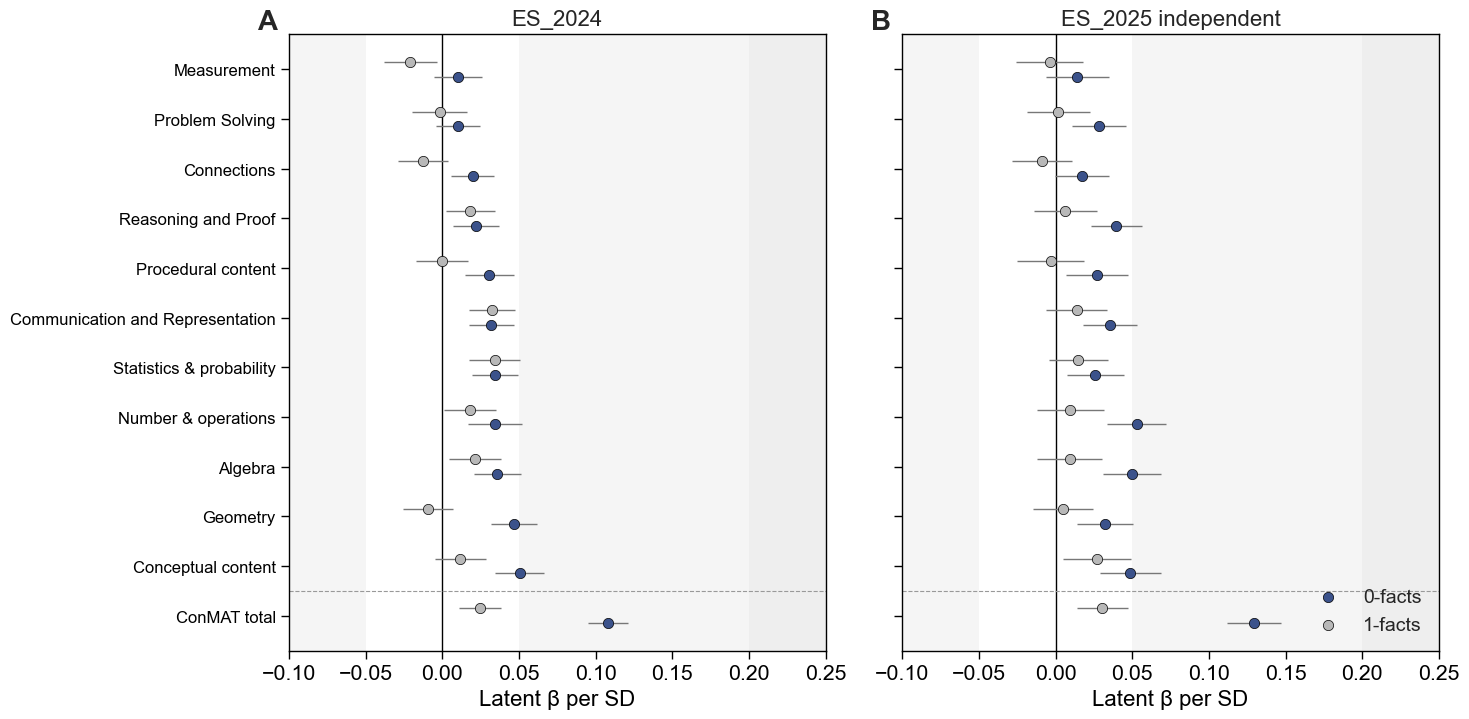

In [8]:
def beta_ci(df):
    return df.assign(blo=beta(df.lo), bhi=beta(df.hi))
F = pd.concat([disc, conf]); F = F[((F.indicator == "ConMAT total") & (F.model == "M1")) | ((F.indicator != "ConMAT total") & (F.model == "M2"))]
F = beta_ci(F)
order = ["ConMAT total"] + list(m2z.sort_values("beta").indicator[::-1])
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), sharey=True)
for ax, s in zip(axes, F["sample"].unique()):
    for lo_, hi_, a_ in ((.05, .20, .5), (.20, .40, .9)):
        for sgn in (1, -1):
            ax.axvspan(*sorted((sgn * lo_, sgn * hi_)), color="#EDEDED", alpha=a_, lw=0, zorder=0)
    ax.axvline(0, color="black", lw=1, zorder=1)
    for k, (ft, col, dy, lab) in enumerate((("zero", C_ZERO, -.15, "0-facts"), ("one", C_OTHER, .15, "1-facts"))):
        g = F[(F["sample"] == s) & (F.outcome == ft)].set_index("indicator").reindex(order)
        y = np.arange(len(order)) + dy
        ax.errorbar(g.beta, y, xerr=[g.beta - g.blo, g.bhi - g.beta], fmt="none", ecolor="#777777", elinewidth=1, zorder=2)
        ax.scatter(g.beta, y, s=55, color=col, edgecolor="black", lw=.5, zorder=3, label=lab)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=FONT_MED - 4); ax.invert_yaxis()
    ax.set_xlim(-.1, .25); ax.set_xlabel("Latent β per SD", fontsize=FONT_MED); ax.set_title(s, fontsize=FONT_MED)
axes[0].axhline(.5, color="#999999", lw=.8, ls="--")
axes[1].axhline(.5, color="#999999", lw=.8, ls="--")
axes[1].legend(frameon=False, fontsize=FONT_MED - 2, loc="lower right")
for a_, letter in zip(axes, "AB"):
    a_.text(-.02, 1.04, letter, transform=a_.transAxes, fontweight="bold", fontsize=FONT_BIG, va="top", ha="right")
fig.tight_layout(); paint_it_black(list(axes))
for ext in ("pdf", "png"):
    fig.savefig(PLOTS / f"zero_rule_correlates_conmat.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## Conclusions
The summary cell below is filled from the numbers above; the interpretation is the last cell.

In [9]:
ct = tot.set_index(["sample", "outcome"]).beta
print(f"- General curricular maths (ConMAT total) predicts the zero rule beyond multiplication fluency and speed: "
      f"β {ct[(DISC, 'zero')]:+.2f} ({DISC}), {ct[(CONF + ' independent', 'zero')]:+.2f} ({CONF}, independent) — Kraft "
      f"{kraft(ct[(CONF + ' independent', 'zero')])}; on 1-facts {ct[(DISC, 'one')]:+.2f} / {ct[(CONF + ' independent', 'one')]:+.2f}.")
rep = cz[cz.replicated].sort_values("beta", ascending=False)
print(f"- Beyond the rest of ConMAT: {len(HITS)} hits in {DISC}, {len(rep)} replicated in {CONF} "
      f"({', '.join(f'{i} {b:+.3f}' for i, b in zip(rep.indicator, rep.beta))}); Kraft {'/'.join(sorted(set(rep.beta.map(kraft)), reverse=True))}; the same subscores do not "
      f"predict 1-facts (max |β| {one.loc[HITS].beta.abs().max():.3f}).")
print(f"- COSMOS: WM {cos.set_index('factor').beta['working_memory']:+.2f}, matrices {cos.set_index('factor').beta['reasoning']:+.2f} "
      f"(both shrink with ConMAT total held: {cos.set_index('factor').loc['working_memory', 'OR + ConMAT total']}, "
      f"{cos.set_index('factor').loc['reasoning', 'OR + ConMAT total']}).")
print(f"- Socio-emotional (exploratory): Holm < .05 only for {', '.join(emo.loc[emo.p_holm < .05, 'subarea']) or 'none'}.")

- General curricular maths (ConMAT total) predicts the zero rule beyond multiplication fluency and speed: β +0.11 (ES_2024), +0.13 (ES_2025, independent) — Kraft medium; on 1-facts +0.02 / +0.03.
- Beyond the rest of ConMAT: 9 hits in ES_2024, 8 replicated in ES_2025 (Number & operations +0.053, Algebra +0.050, Conceptual content +0.049, Reasoning and Proof +0.040, Communication and Representation +0.036, Geometry +0.032, Procedural content +0.027, Statistics & probability +0.026); Kraft small/medium; the same subscores do not predict 1-facts (max |β| 0.027).
- COSMOS: WM +0.14, matrices +0.13 (both shrink with ConMAT total held: 1.23 [0.94, 1.60], 1.19 [0.93, 1.52]).
- Socio-emotional (exploratory): Holm < .05 only for Self-concept.


## Sanity checks

In [10]:
assert not d5.index.isin(d4.index).any()                                  # confirmation is independent
assert set(HITS) <= set(TAGS) and len(m2z) == len(TAGS)
assert (d4[[f"s|{t}" for t in TAGS]].abs().max() < 10).all()             # z-scores are finite and sane
assert abs(d4["s|all"].mean()) < .1 and abs(d4["s|all"].std() - 1) < .1   # standardised within test
assert cs["s|all"].notna().mean() > .9                                    # COSMOS students found in ConMAT
print("ok")

ok


## Interpretation

**1. The zero rule goes with general curricular maths, not with fact fluency.** Among students who are equally accurate
and equally fast on ordinary facts, one SD more ConMAT goes with a latent zero-rule propensity 0.11 SD higher (ES_2024)
and 0.13 SD higher in new students (ES_2025) — Kraft *medium*, replicated. The same score barely touches the 1-facts
(β .03). So what predicts knowing `n×0 = 0` is not "being good at multiplication" (already held) nor "being a good
test-taker" (that would lift the 1-facts too): it is how much maths the student understands beyond the tables. This
fits the stable, transferable student-level ability found in `sequential_zero_consistency`.

**2. No particular content area: a broad, mostly conceptual signal.** Holding the rest of ConMAT, 8 of the 9 subscores
flagged in ES_2024 still add a little in ES_2025 (β .03–.05), across number, algebra, geometry and statistics and across
processes; measurement and problem solving add nothing. With each family fitted jointly, **conceptual content** is the most
consistent single piece (β .047 and .046 in the two years), procedural content about half of that. None of this shows on
the 1-facts. Read: the zero rule is a marker of conceptual understanding in general (knowing what an operation *does*),
not of a topic. Two caveats keep this modest: the unique part of every subscore is small next to the general factor
(β ≤ .05 vs .11–.13), and subscores have 3–8 items, so the ranking among them (.03 vs .05) is within their noise.

**3. WM and matrices overlap with ConMAT — in the COSMOS students only.** WM and matrices exist only for the 363
COSMOS students (7y → age 9, mostly MX), so every statement here is about that subsample, not the 64k / 44k ES samples.
In those students the two measures are correlated (ConMAT with matrices r = .49, with WM r = .26, measured two years
apart) and predict the same part of the zero rule: WM and matrices give β .14 and .13, ConMAT β .17; holding ConMAT, WM
loses ~20% of its log-OR and matrices ~25%; holding WM + matrices, ConMAT loses ~50%. In a logistic model adding a
predictor that is *unrelated* to the others tends to make the other coefficients grow (non-collapsibility), so this
shrinkage reflects real shared information. It does not say which way it runs: WM / reasoning at 7 may help children
learn the maths ConMAT measures at 9, or both may reflect a common factor (general ability, school). The shrinkage
percentages rest on wide CIs (each OR's CI reaches 1) and should be read as "a substantial part is shared", not as
precise shares. Whether the same holds for the ES samples, where ConMAT carries the medium effect, is untested until the
COSMOS 2024-25 cohort reaches the zero facts. The negative early-numeracy factors (number knowledge, arithmetic fluency)
are the suppression already described in #54 and are not interpreted.

**4. Socio-emotional: one lead, not a result.** Only math self-concept survives Holm (β −.13, shrinking to −.10 with
ConMAT held; no effect on 1-facts). The scale seems keyed so that higher = more negative, so this would mean a *better*
self-concept goes with a better zero rule — but the keying is unverified, n ≈ 1,000 in 26 schools and the measure
mostly precedes A998 by a year. Hypothesis-generating only.

**Limits.** Correlational and concurrent (ConMAT and A998 in the same year): this says what the zero rule *goes with*,
not what causes it. Only one ConMAT item ("properties of multiplication") could be identified and removed as possible
zero content; others could not be checked without the item text, and any `×0` item left in would inflate point 1
(the 1-fact nulls argue against general test-taking, not against shared content). ConMAT is optional for schools, so
the linked students are a selected subset of A998. Kraft's benchmarks were built for intervention effects; here they
grade associations.

**For the paper.** "Knowing the zero rule is tied to general, mostly conceptual mathematical understanding (medium,
replicated), not to multiplication fluency; in the subsample with early cognitive measures, a substantial part of this
signal is shared with working memory and fluid reasoning."
Next: check the ConMAT items for zero content; the large COSMOS 2024-25 cohort (2027) can test WM / matrices against
ConMAT with enough power.
